## Limpieza

In [2]:
import pandas as pd

tempV = []
tempR = []
tempM = []

masas = []				#gramos
voltajes = []			#volts
resistencias = []	#kOhms

with open('.\\datos\\datos.txt', 'r') as file:
	data_raw = file.readlines()

for i in range(5, len(data_raw), 9):
	tempV.append(data_raw[i])
	tempR.append(data_raw[i+1])
	tempM.append(data_raw[i+2])

for t in tempM:
	a = t.replace('Lectura Balanza: ', '')
	b = a.replace(' (crudos/kg segun factor)\n', '')
	masas.append(b)

for t in tempV:
	a = t.replace('Voltaje FSR: ', '')
	b = a.replace(' V\n', '')
	voltajes.append(b)

for t in tempR:
	a = t.replace('Resistencia FSR: ', '')
	b = a.replace(' kOhm\n', '')
	c = b.replace('> 10 MOhm (Circuito abierto / Sin carga)\n','10000')
	resistencias.append(c)

df = pd.DataFrame({
	'Voltaje FSR':voltajes,
	'Resistencia FSR':resistencias,
	'Masa':masas
})

# print(resistencias) 	

# Descomentar en caso de emergencia :)
# df.to_csv("datos.csv", index=False, encoding="utf-8")
df.sort_values(by='Resistencia FSR', inplace=True)
display(df)

,Voltaje FSR,Resistencia FSR,Masa
62,4.572,0.94,1419.879
61,4.568,0.94,1419.839
60,4.562,0.96,1419.643
54,4.491,1.13,1096.736
53,4.489,1.14,1096.795
...,...,...,...
21,2.830,7.67,227.455
20,2.827,7.69,227.539
19,2.811,7.79,227.751
84,0.070,700.42,124.995


# Gráficas

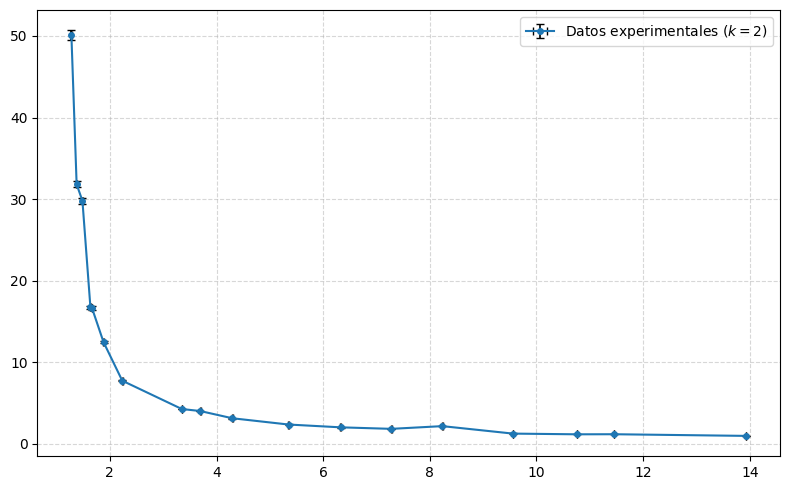

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('.\\datos\\datos_promedio.csv')
df = df.sort_values(by='Masa [g]').reset_index(drop=True)

# Fuerza
g = 9.81
df['Fuerza [N]'] = (df['Masa [g]'] / 1000.0) * g
u_F = g * (0.001 / np.sqrt(12))  # 0.00283 N
U_F = 2.0 * u_F                 # 0.00566 N

# Voltaje
delta_V = 5.0 / 1023.0
u_V = delta_V / np.sqrt(12)      # 1.411 mV
U_V = 2.0 * u_V                 # 2.822 mV

# Resistencia
R_ref = 10.0  # kOhm
u_Rref = (0.01 * R_ref) / np.sqrt(3)  # 0.0577 kOhm

V = df['Voltaje FSR [V]']
R = df['Resistencia FSR [kOhm]']

dR_dRref = (5.0 / V) - 1.0
dR_dV = - (5.0 * R_ref) / (V**2)

df['u_R [kOhm]'] = np.sqrt((dR_dRref * u_Rref)**2 + (dR_dV * u_V)**2)
df['U_R [kOhm]'] = 2.0 * df['u_R [kOhm]']

# Gráfica con barras de error
plt.figure(figsize=(8, 5))
plt.errorbar(
    df['Fuerza [N]'], df['Resistencia FSR [kOhm]'],
    xerr=U_F, yerr=df['U_R [kOhm]'],
    fmt='o-', color='tab:blue', ecolor='black',
    elinewidth=1.2, capsize=3, markersize=4,
    label='Datos experimentales ($k=2$)'
)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Ajuste

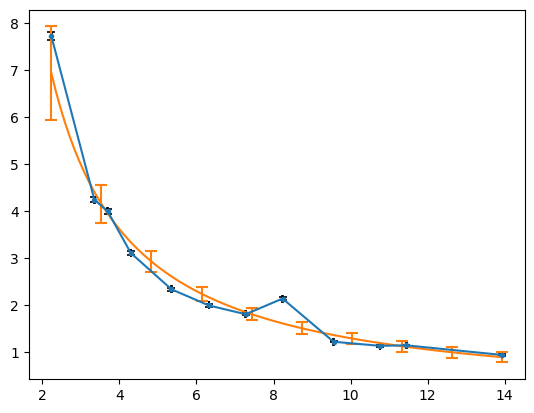

a = 16.9637
b = 1.1150


In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def modelo(m, b, x):
    return b - (m * x)

data = pd.read_csv('.\\datos\\datos_promedio.csv', sep=',')
data.sort_values(by='Masa [g]', inplace=True)
data.query('`Masa [g]` > 191.74725', inplace=True)

masa = data['Masa [g]'].to_numpy()
fuerza = masa * 9.81 / 1000.0
log_fuerza = np.log(fuerza)
resistencia = data['Resistencia FSR [kOhm]'].to_numpy()
log_resistencia = np.log(resistencia)

voltaje = data['Voltaje FSR [V]'].to_numpy()
u_V = (5.0 / 1023.0) / np.sqrt(12)
u_Rref = 0.1 / np.sqrt(3)

dR_dV = -50.0 / (voltaje**2)
dR_dRref = (5.0 / voltaje) - 1.0

u_R = np.sqrt((dR_dRref * u_Rref)**2 + (dR_dV * u_V)**2)
U_R = 2.0 * u_R
U_F = 2.0 * 9.81 * (0.001 / np.sqrt(12))

semilla = [np.log(1), 0.7]


potp, pcov = curve_fit(modelo, log_fuerza, log_resistencia, semilla, sigma=u_R / resistencia, absolute_sigma=False)

m, b = potp
a = np.exp(m)


f_fit = np.linspace(fuerza.min(), fuerza.max(), 100)
r_fit = a / (f_fit**b)


f_pts = np.linspace(fuerza.min(), fuerza.max(), 10)
log_f_pts = np.log(f_pts)
r_pts = a / (f_pts**b)
var_log_r_pts = pcov[0, 0] + (log_f_pts**2) * pcov[1, 1] - 2 * log_f_pts * pcov[0, 1]
U_r_pts = 2.0 * r_pts * np.sqrt(var_log_r_pts)


plt.errorbar(fuerza, resistencia, xerr=U_F, yerr=U_R, fmt='o-', color='tab:blue', ecolor='black', elinewidth=1.2, capsize=3, capthick=1.2, markersize=3)

plt.plot(f_fit, r_fit, color='tab:orange')
plt.errorbar(f_pts, r_pts, yerr=U_r_pts, fmt='none', ecolor='tab:orange', elinewidth=1.5, capsize=4, capthick=1.5)

plt.show()

print(f"a = {a:.4f}")
print(f"b = {b:.4f}")

In [ ]:
import numpy as np

a = np.abs(1)
print(a)

1
